# Geochemical Exploratory Analysis — Multi-Region (Cordilleran / Superior / Grenville)

Runs the same workflow over **each study area** and produces, per region:

1. **Scree plot** — variance explained by each PC
2. **PCA figure** — PC1–PC2 scatter with marginal density curves + element biplot (Chetan-style)
3. **LDA plot** — supervised separability of REE vs background, with cross-validated AUC

**Pipeline per region**
load geochem + occurrences → IDW-assign geochem to occurrences (positives) →
background samples far from occurrences (negatives) → KNN-impute → CLR → standardise → PCA & LDA.

> Positives are IDW-interpolated; background uses measured values. This provenance
> difference, sparse sampling, and small positive counts are discussed in the notes.


## 1. Configuration

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.stats import gaussian_kde
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import cross_val_score

# ---- One entry per study area. Fill in paths for Superior & Grenville
#      once you have their files (set to None to skip a region). ----
REGIONS = {
    "Cordilleran": {
        "geo": "../geochem/Geochemistry_Cordilleran_Clip.csv",
        "dep": "../geochem/CarbonatitehostREE_Cordilleran_Clip.csv",
    },
    "Superior": {
        "geo": "../geochem/Geochemistry_Superior_Clip.csv",   # e.g. "Geochemistry_Superior_Clip.csv"
        "dep": "../geochem/CarbonatitehostREE_Superior_Clip.csv",   # e.g. "CarbonatitehostREE_Superior_Clip.csv"
    },
    "Grenville": {
        "geo": "../geochem/Geochemistry_Grenville_Clip.csv",
        "dep": "../geochem/CarbonatitehostREE_Grenville_Clip.csv",
    },
}

# Indicator-element suite (REE + carbonatite pathfinders + base/transition metals)
ELEMENT_COLS = [
    'fe2o3','fe2o3_tot','feo','feo_tot','sio2','tio2','al2o3', 'mgo','cao','mno','k2o','p2o5',"ba_ppm", "sr_ppm", "zn_ppm", "cu_ppm", "ni_ppm", "pb_ppm", "cr_ppm", "rb_ppm",
    "y_ppm", "ag_ppm", "co_ppm", "nb_ppm", "zr_ppm", "th_ppm", "la_ppm", "mo_ppm",
    "as_ppm", "ce_ppm", "u_ppm", "v_ppm", "sb_ppm", "ta_ppm", "sc_ppm",
]

MIN_ELEMENTS     = 8  # Reduced from 12 for sparse geochemistry (Grenville)
SEARCH_RADIUS_KM = 25.0  # Increased from 25 km to capture Grenville occurrences
K_NEIGHBOURS     = 8
IDW_POWER        = 2.0
BUFFER_KM        = 10.0
N_BACKGROUND     = 400
KNN_IMPUTE_K     = 5
RANDOM_SEED      = 42

ELEM_LABEL = {c: c.replace("_ppm", "").capitalize() for c in ELEMENT_COLS}

## 2. Helper functions

In [2]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance (km). lat1/lon1 scalar, lat2/lon2 arrays."""
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))


def idw(distances, values, power):
    mask = ~np.isnan(values)
    if mask.sum() == 0:
        return np.nan
    d, v = distances[mask], values[mask]
    if np.any(d < 1e-6):
        return v[d < 1e-6].mean()
    w = 1.0 / (d ** power)
    return np.sum(w * v) / np.sum(w)


def clr(df_elem):
    X = df_elem.astype(float).copy()
    mp = X[X > 0].min().min()
    X = X.mask(X <= 0, mp / 2.0)
    logX = np.log(X)
    return logX.sub(logX.mean(axis=1), axis=0)


## 2.5 Missing Element Analysis (per region)

Reads each raw geochem CSV and reports, for every element in `ELEMENT_COLS`, the
percentage of rows where the value is absent (NaN) **or the column does not exist at
all**. This gives a data-quality overview before imputation.

- Green  < 20 % missing  
- Orange 20–50 % missing  
- Red    > 50 % missing (column may be entirely absent in that region)

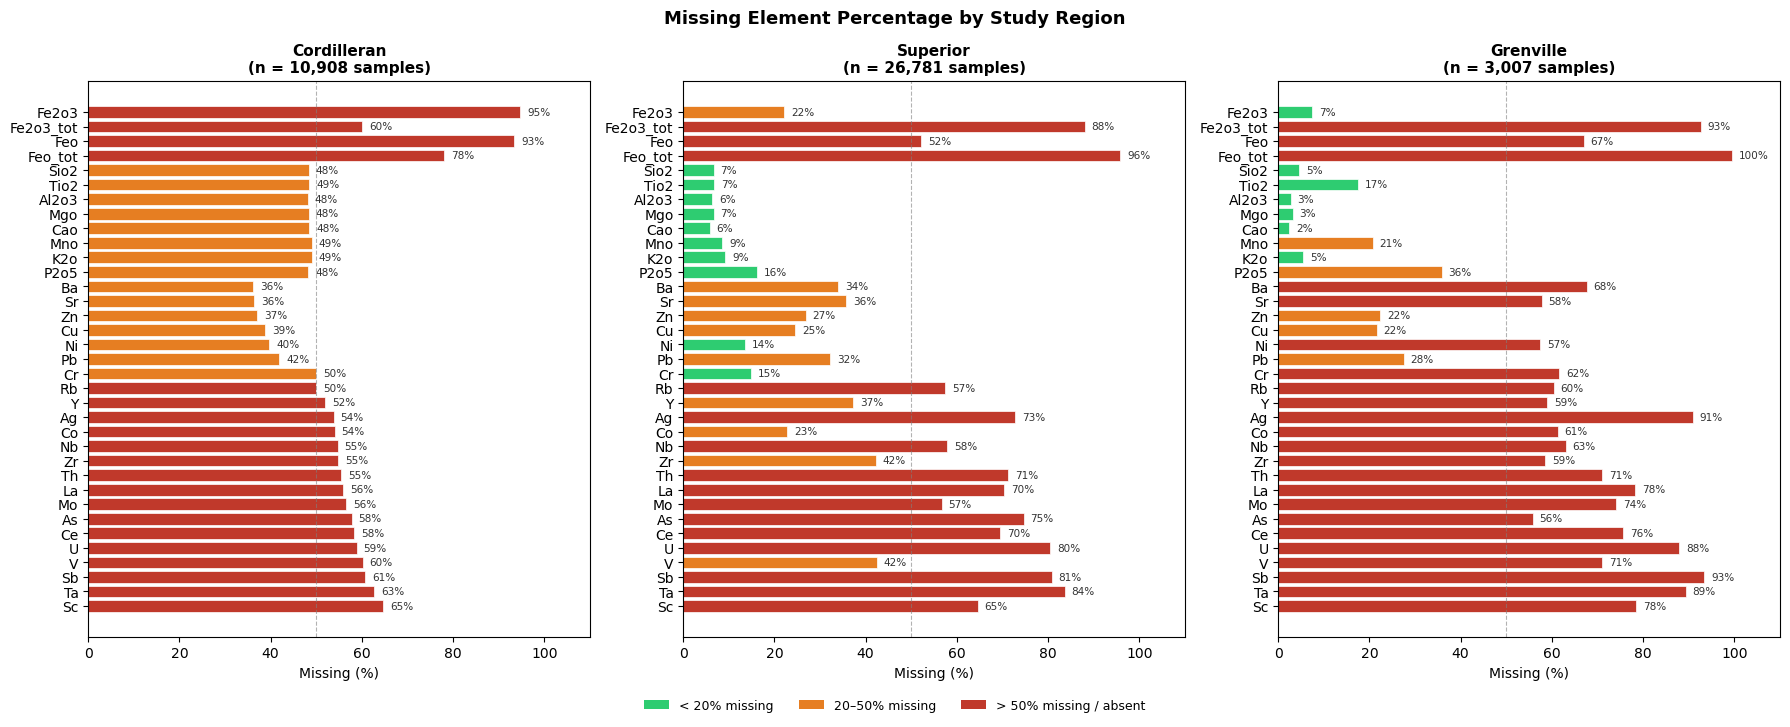


Missing % by element and region:
           Cordilleran  Superior  Grenville
Fe2o3             94.7      22.1        7.4
Fe2o3_tot         60.0      88.0       92.7
Feo               93.4      52.2       66.9
Feo_tot           78.1      95.8       99.6
Sio2              48.3       6.7        4.6
Tio2              48.5       6.8       17.4
Al2o3             48.1       6.3        2.7
Mgo               48.4       6.6        3.2
Cao               48.4       5.8        2.4
Mno               49.0       8.5       20.7
K2o               49.0       9.3        5.4
P2o5              48.3      16.2       35.8
Ba                36.1      34.0       67.6
Sr                36.4      35.7       57.7
Zn                37.1      26.8       22.4
Cu                38.7      24.6       21.5
Ni                39.7      13.6       57.4
Pb                41.9      32.2       27.5
Cr                50.0      14.8       61.6
Rb                50.0      57.4       60.4
Y                 51.9      37.2       58.

In [5]:
import os

n_regions = sum(1 for p in REGIONS.values() if p["geo"])
fig, axes = plt.subplots(1, n_regions, figsize=(6 * n_regions, 7), squeeze=False)
axes = axes[0]

missing_summary = {}
ax_idx = 0

for name, paths in REGIONS.items():
    geo_path = paths["geo"]
    if not geo_path:
        continue
    ax = axes[ax_idx]; ax_idx += 1

    try:
        header = pd.read_csv(geo_path, nrows=0)
        elems_present = [c for c in ELEMENT_COLS if c in header.columns]

        geo_miss = pd.read_csv(geo_path, usecols=["latitude", "longitude"] + elems_present,
                               low_memory=True)
        n_total = len(geo_miss)

        miss_pct = {}
        for c in ELEMENT_COLS:
            if c in elems_present:
                miss_pct[c] = geo_miss[c].isna().mean() * 100
            else:
                miss_pct[c] = 100.0          # column entirely absent
        del geo_miss
        missing_summary[name] = miss_pct

        labels = [ELEM_LABEL.get(c, c) for c in ELEMENT_COLS]
        values = [miss_pct[c] for c in ELEMENT_COLS]
        colors = ["#c0392b" if v > 50 else "#e67e22" if v > 20 else "#2ecc71" for v in values]

        bars = ax.barh(labels, values, color=colors, edgecolor="white", linewidth=0.5)
        ax.set_xlim(0, 110)
        ax.set_xlabel("Missing (%)", fontsize=10)
        ax.set_title(f"{name}\n(n = {n_total:,} samples)", fontsize=11, fontweight="bold")
        ax.axvline(50, color="grey", lw=0.8, linestyle="--", alpha=0.6)
        ax.invert_yaxis()

        for bar, v in zip(bars, values):
            ax.text(min(v + 1.5, 106), bar.get_y() + bar.get_height() / 2,
                    f"{v:.0f}%", va="center", fontsize=7.5,
                    color="#333333")

    except FileNotFoundError:
        ax.set_title(f"{name}\n(file not found)")
        ax.text(0.5, 0.5, "File not found", transform=ax.transAxes,
                ha="center", va="center", color="red")

# Shared legend
from matplotlib.patches import Patch
legend_elems = [Patch(facecolor="#2ecc71", label="< 20% missing"),
                Patch(facecolor="#e67e22", label="20–50% missing"),
                Patch(facecolor="#c0392b", label="> 50% missing / absent")]
fig.legend(handles=legend_elems, loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, -0.04), fontsize=9, frameon=False)

plt.suptitle("Missing Element Percentage by Study Region", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# ── Summary table ──────────────────────────────────────────────────────────────
if missing_summary:
    df_miss = pd.DataFrame(missing_summary).rename(index=ELEM_LABEL)
    print("\nMissing % by element and region:")
    print(df_miss.round(1).to_string())

#### Positive samples (REE occurrences) are constructed by IDW-interpolating the surrounding geochemical stations within a 25 km search radius of each known carbonatite-hosted REE deposit. For each occurrence, up to the 8 nearest stations are located and their element concentrations are combined using inverse-distance weighting (power = 2), yielding a single interpolated geochemical signature per deposit. Any occurrence whose interpolated result contains fewer than 8 non-missing elements — indicating insufficient nearby sampling coverage — is discarded. Negative samples (background) are drawn directly from measured station values, restricted to stations that lie more than 10 km from any known occurrence and that themselves have at least 8 valid element readings. Up to 400 background stations are randomly selected from this eligible pool. This design means that positives carry a smoothed, interpolated signal while negatives reflect raw measurements, a provenance asymmetry that is acknowledged as a limitation of the approach.

## 3. Per-region processing function

`build_region` does everything up to the standardised feature matrix `Z` and
labels `y` for one region; returns `None` if files are missing or too few
positives survive.


In [11]:
def build_region(name, geo_path, dep_path):
    if not geo_path or not dep_path:
        print(f"[{name}] paths not set — skipping")
        return None
    rng = np.random.default_rng(RANDOM_SEED)
    dep = pd.read_csv(dep_path).dropna(subset=["Latitude", "Longitude"]).reset_index(drop=True)

    # Read only needed columns — full CSV has 192 cols (>300 MB); slim read = ~5 MB
    header = pd.read_csv(geo_path, nrows=0)
    elems  = [c for c in ELEMENT_COLS if c in header.columns]
    needed = ["latitude", "longitude"] + elems
    geo = pd.read_csv(geo_path, usecols=needed).dropna(subset=["latitude", "longitude"]).reset_index(drop=True)
    glat, glon = geo["latitude"].values, geo["longitude"].values
    gelem = geo[elems].values
    # Pre-compute mask before freeing geo — avoids keeping 192-col DataFrame in memory
    enough = geo[elems].notna().sum(axis=1).values >= MIN_ELEMENTS
    del geo

    # POSITIVES: IDW-assign to occurrences
    pos_rows = []
    for _, d in dep.iterrows():
        dist = haversine_km(d["Latitude"], d["Longitude"], glat, glon)
        within = np.where(dist <= SEARCH_RADIUS_KM)[0]
        if len(within) == 0:
            pos_rows.append([np.nan]*len(elems)); continue
        within = within[np.argsort(dist[within])[:K_NEIGHBOURS]]
        pos_rows.append([idw(dist[within], gelem[within, j], IDW_POWER) for j in range(len(elems))])
    pos = pd.DataFrame(pos_rows, columns=elems)
    pos = pos[pos[elems].notna().sum(axis=1) >= MIN_ELEMENTS].reset_index(drop=True)
    pos["label"] = 1

    # NEGATIVES: real samples far from occurrences
    mind = np.full(len(glat), np.inf)
    for _, d in dep.iterrows():
        mind = np.minimum(mind, haversine_km(d["Latitude"], d["Longitude"], glat, glon))
    far_idx = np.where((mind > BUFFER_KM) & enough)[0]
    if len(pos) < 5 or len(far_idx) < 10:
        print(f"[{name}] too few samples (pos={len(pos)}, neg_pool={len(far_idx)}) — skipping")
        return None
    chosen = rng.choice(far_idx, size=min(N_BACKGROUND, len(far_idx)), replace=False)
    neg = pd.DataFrame(gelem[chosen], columns=elems); neg["label"] = 0

    data = pd.concat([pos, neg], ignore_index=True)

    # impute (log-scale KNN) -> CLR -> standardise
    X = data[elems].astype(float).copy()
    mp = X[X > 0].min().min()
    X = X.mask(X <= 0, mp/2.0)
    X_imp = pd.DataFrame(np.exp(KNNImputer(n_neighbors=KNN_IMPUTE_K).fit_transform(np.log(X))), columns=elems)
    Z = StandardScaler().fit_transform(clr(X_imp))
    y = data["label"].values
    print(f"[{name}] positives={int((y==1).sum())}, background={int((y==0).sum())}, elements={len(elems)}")
    return {"name": name, "Z": Z, "y": y, "elems": elems}


## 4. Plotting functions

Three figures per region: scree, PCA (scatter + density + biplot), LDA.


In [12]:
def plot_scree(res, var):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(range(1, len(var)+1), var*100, "o-", color="#8b1a1a")
    for i, v in enumerate(var, 1):
        ax.annotate(f"{v*100:.1f}%", (i, v*100), textcoords="offset points",
                    xytext=(0, 6), fontsize=7, ha="center")
    ax.set_xlabel("Principal Component"); ax.set_ylabel("Variance Explained (%)")
    ax.set_title(f"{res['name']}: Variance Explained")
    plt.tight_layout(); plt.show()


def plot_pca(res, pca, scores, var):
    elems, y, comp = res["elems"], res["y"], pca.components_
    classes = [(0, "Background", "#9bb8cc"), (1, "REE occurrence", "#c0392b")]
    fig = plt.figure(figsize=(13, 6))
    gs = GridSpec(2, 3, width_ratios=[4,1,4], height_ratios=[1,4], wspace=0.05, hspace=0.05)
    ax = fig.add_subplot(gs[1,0]); axt = fig.add_subplot(gs[0,0], sharex=ax)
    axr = fig.add_subplot(gs[1,1], sharey=ax); axb = fig.add_subplot(gs[:,2])
    for lab, nm, col in classes:
        m = y == lab
        ax.scatter(scores[m,0], scores[m,1], s=20, alpha=0.55, label=nm,
                   facecolor=(col if lab==1 else "none"), edgecolor=col, linewidth=0.6)
    ax.set_xlabel(f"PC1 ({var[0]*100:.1f}% variance)")
    ax.set_ylabel(f"PC2 ({var[1]*100:.1f}% variance)")
    ax.legend(loc="lower right", fontsize=8)
    ax.set_title(f"(a) {res['name']}", loc="left", fontweight="bold")
    gx = np.linspace(scores[:,0].min(), scores[:,0].max(), 200)
    gy = np.linspace(scores[:,1].min(), scores[:,1].max(), 200)
    for lab, nm, col in classes:
        m = y == lab
        axt.plot(gx, gaussian_kde(scores[m,0])(gx), color=col, lw=1.4)
        axr.plot(gaussian_kde(scores[m,1])(gy), gy, color=col, lw=1.4)
    axt.axis("off"); axr.axis("off")
    for j, c in enumerate(elems):
        vx, vy = comp[0,j], comp[1,j]
        axb.arrow(0,0,vx,vy, head_width=0.015, color="black", lw=0.8, length_includes_head=True)
        axb.text(vx*1.12, vy*1.12, ELEM_LABEL.get(c, c), fontsize=8, ha="center", va="center")
    lim = np.abs(comp[:2]).max()*1.25
    axb.set_xlim(-lim, lim); axb.set_ylim(-lim, lim)
    axb.axhline(0, color="grey", lw=0.4); axb.axvline(0, color="grey", lw=0.4)
    axb.set_xlabel("PC1"); axb.set_ylabel("PC2")
    axb.set_title("(b)", loc="left", fontweight="bold")
    plt.show()


def plot_lda(res, proj):
    y = res["y"]
    fig, ax = plt.subplots(figsize=(7, 4))
    for lab, nm, col in [(0,"Background","#9bb8cc"), (1,"REE occurrence","#c0392b")]:
        m = y == lab
        grid = np.linspace(proj.min(), proj.max(), 300)
        ax.fill_between(grid, gaussian_kde(proj[m])(grid), alpha=0.4, color=col, label=nm)
        ax.plot(grid, gaussian_kde(proj[m])(grid), color=col, lw=1.5)
        ax.plot(proj[m], np.full(m.sum(), -0.01), "|", color=col, alpha=0.5, ms=8)
    ax.set_xlabel("LDA discriminant axis"); ax.set_ylabel("Density")
    ax.set_title(f"{res['name']}: LDA separation (REE vs background)")
    ax.legend(); plt.tight_layout(); plt.show()


## 5. Run all regions

[Cordilleran] positives=38, background=400, elements=23

===== Cordilleran =====
Explained variance: PC1=14.9%, PC2=11.4%, PC3=9.0%, PC4=7.5%, PC5=6.7%


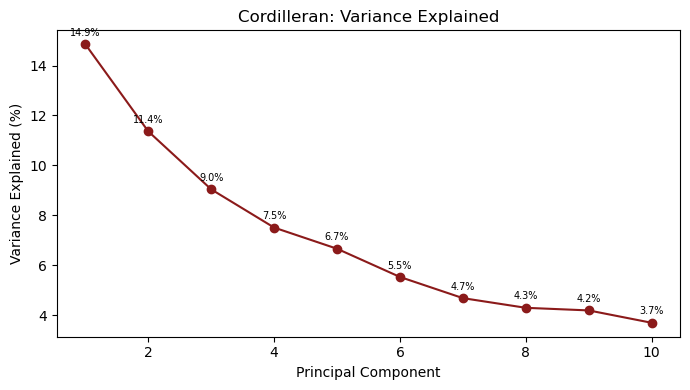

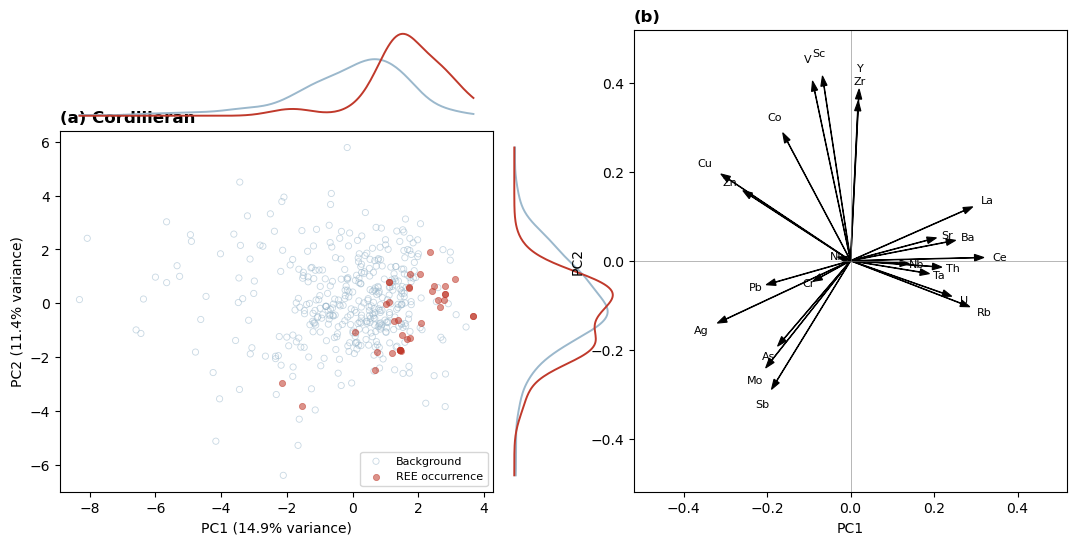

Top |PC1| loadings:
Ce    0.319
Ag    0.319
Cu    0.311
La    0.293
Rb    0.285
Zn    0.258
Ba    0.252
U     0.242
dtype: float64


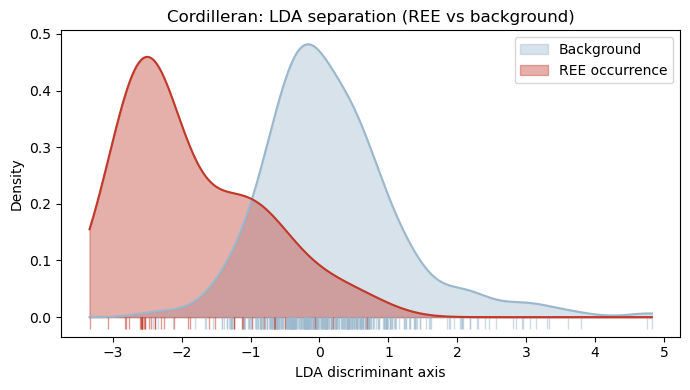

Cordilleran LDA 5-fold CV AUC: 0.888 +/- 0.023
[Superior] positives=7, background=400, elements=23

===== Superior =====
Explained variance: PC1=25.5%, PC2=11.0%, PC3=9.5%, PC4=6.4%, PC5=5.3%


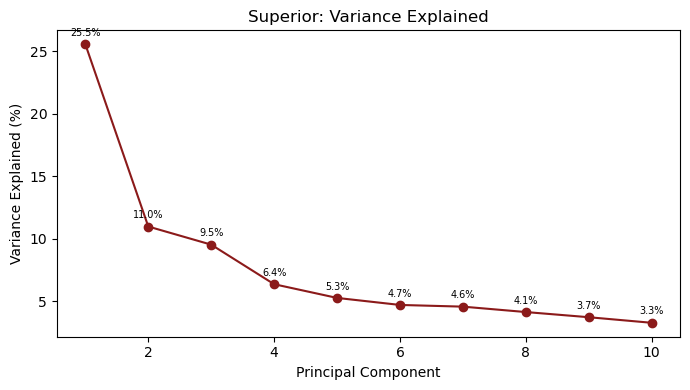

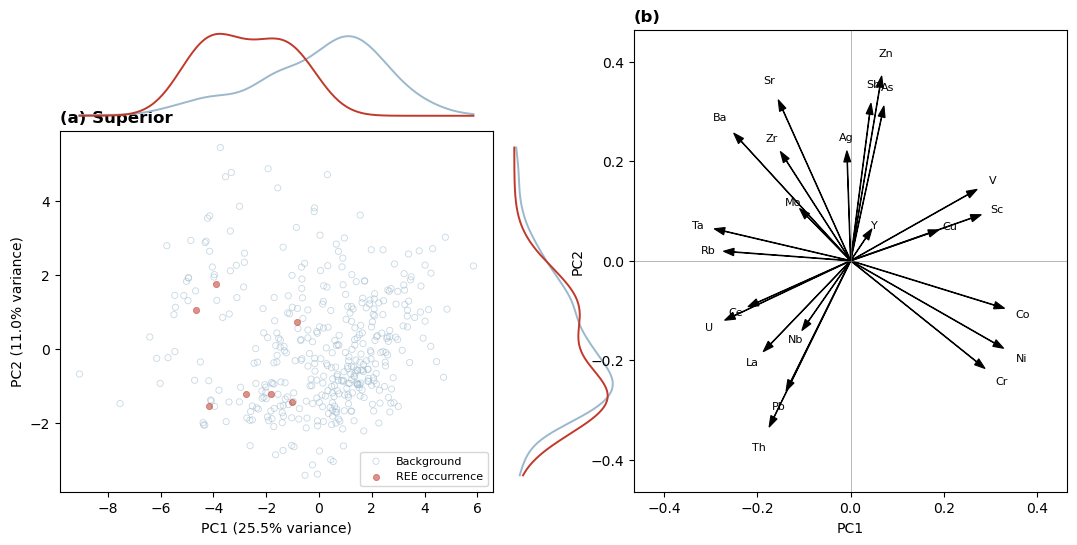

Top |PC1| loadings:
Co    0.330
Ni    0.328
Ta    0.293
Cr    0.288
Sc    0.280
Rb    0.273
V     0.271
U     0.270
dtype: float64


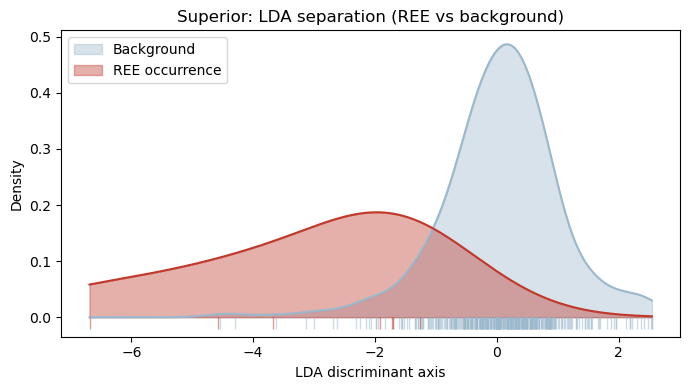

Superior LDA 5-fold CV AUC: 0.841 +/- 0.105
[Grenville] too few samples (pos=3, neg_pool=1280) — skipping


In [13]:
results = {}
for name, paths in REGIONS.items():
    res = build_region(name, paths["geo"], paths["dep"])
    if res is None:
        continue

    # PCA
    pca = PCA(n_components=min(10, len(res["elems"]))).fit(res["Z"])
    scores = pca.transform(res["Z"]); var = pca.explained_variance_ratio_

    print(f"\n===== {name} =====")
    print("Explained variance:", ", ".join(f"PC{i}={v*100:.1f}%" for i, v in enumerate(var[:5], 1)))
    plot_scree(res, var)
    plot_pca(res, pca, scores, var)

    # PC1 loadings
    load = pd.Series(pca.components_[0], index=[ELEM_LABEL.get(c,c) for c in res["elems"]])
    print("Top |PC1| loadings:"); print(load.abs().sort_values(ascending=False).head(8).round(3))

    # LDA + CV AUC
    proj = LinearDiscriminantAnalysis().fit_transform(res["Z"], res["y"]).ravel()
    plot_lda(res, proj)
    auc = cross_val_score(LinearDiscriminantAnalysis(), res["Z"], res["y"], cv=5, scoring="roc_auc")
    print(f"{name} LDA 5-fold CV AUC: {auc.mean():.3f} +/- {auc.std():.3f}")

    results[name] = {"pca": pca, "var": var, "auc": auc.mean(), 
                     "Z_original": res["Z"], "y": res["y"]}

## 6. Cross-region summary

In [14]:
if results:
    summ = pd.DataFrame({
        "PC1_%": {k: v["var"][0]*100 for k, v in results.items()},
        "PC2_%": {k: v["var"][1]*100 for k, v in results.items()},
        "LDA_AUC": {k: v["auc"] for k, v in results.items()},
    }).round(3)
    print(summ.to_string())
else:
    print("No regions processed — set file paths in REGIONS.")


              PC1_%   PC2_%  LDA_AUC
Cordilleran  14.855  11.364    0.888
Superior     25.540  10.971    0.841


## 7. Notes & limitations

- **Provenance mismatch:** positives are IDW-interpolated, background uses measured
  values — interpolation smooths the positive signal, so separability estimates are
  conservative.
- **Sparse, uneven geochemistry:** full-region grid interpolation was deliberately
  avoided to prevent fabricating values where no samples exist.
- **Small positive counts** (tens of points): treat LDA AUC as *indicative*.
- **PCA is linear & unsupervised:** weak PC1–PC2 separation does not preclude a
  non-linear, semi-supervised model (e.g. DevNet) separating the classes.
- **Per-region element sets** may differ slightly if some columns are absent in a
  region's file (handled automatically); compare loadings with that in mind.


In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

print("\n" + "="*70)
print("MODEL COMPARISON: Original features vs PCA features")
print("="*70)

for region_name, region_data in results.items():
    print(f"\n{'='*70}")
    print(f"REGION: {region_name}")
    print(f"{'='*70}")
    
    # Get the data for this region
    Z_original = region_data["Z_original"]  # Original standardized features
    Z_pca = region_data["pca"].transform(Z_original)[:, :10]  # Use first 10 PCs
    y = region_data["y"]
    
    print(f"Data shape: {y.sum()} positives, {(y==0).sum()} negatives")
    print(f"Original features: {Z_original.shape[1]}")
    print(f"PCA features: {Z_pca.shape[1]}\n")
    
    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_SEED),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED),
        "SVM (RBF)": SVC(kernel='rbf', probability=True, random_state=RANDOM_SEED),
    }
    
    print(f"{'Model':<25} {'Original Features':<20} {'PCA Features':<20}")
    print("-" * 65)
    
    for model_name, model in models.items():
        # Cross-validation on original features
        scores_orig = cross_validate(model, Z_original, y, cv=5, scoring="roc_auc")
        auc_orig = scores_orig["test_score"].mean()
        
        # Cross-validation on PCA features
        scores_pca = cross_validate(model, Z_pca, y, cv=5, scoring="roc_auc")
        auc_pca = scores_pca["test_score"].mean()
        
        print(f"{model_name:<25} {auc_orig:.3f} ± {scores_orig['test_score'].std():.3f}    "
              f"{auc_pca:.3f} ± {scores_pca['test_score'].std():.3f}")


MODEL COMPARISON: Original features vs PCA features

REGION: Cordilleran
Data shape: 38 positives, 400 negatives
Original features: 23
PCA features: 10

Model                     Original Features    PCA Features        
-----------------------------------------------------------------
Logistic Regression       0.906 ± 0.032    0.891 ± 0.018
Random Forest             0.989 ± 0.006    0.938 ± 0.052
SVM (RBF)                 0.941 ± 0.039    0.923 ± 0.032

REGION: Superior
Data shape: 7 positives, 400 negatives
Original features: 23
PCA features: 10

Model                     Original Features    PCA Features        
-----------------------------------------------------------------
Logistic Regression       0.838 ± 0.167    0.719 ± 0.264
Random Forest             0.679 ± 0.290    0.563 ± 0.230
SVM (RBF)                 0.831 ± 0.172    0.689 ± 0.217
